<a href="https://colab.research.google.com/github/sampath0711/DEEP-LEARNING/blob/main/Skill/Skill_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics

In [ ]:
import os
import glob
import time
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

if not torch.cuda.is_available():
    raise RuntimeError("GPU not found. In Colab, select Runtime > Change runtime type > GPU.")

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
GPU: Tesla T4


In [ ]:
# Load the pretrained YOLOv8 nano model
model = YOLO("yolov8n.pt")
model.to("cuda")
model.model.eval()

print("Model loaded: YOLOv8n")
print("Device: CUDA")

Model loaded: YOLOv8n
Device: CUDA


In [ ]:
# Evaluate on the COCO128 validation dataset
# Ultralytics downloads the dataset automatically when needed.
DATA_YAML = "coco128.yaml"

validation = model.val(
    data=DATA_YAML,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=False,
    verbose=True
)

map50 = float(validation.box.map50)
map50_95 = float(validation.box.map)

print("mAP@0.5:", round(map50, 4))
print("mAP@0.5:0.95:", round(map50_95, 4))

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

WARNING ⚠️ Dataset 'coco128.yaml' images not found, missing path '/content/datasets/coco128/images/train2017'
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 3.4Kfiles/s 0.1s
Dataset download success ✅ (0.5s), saved to /content/datasets

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1100.8±893.8 MB/s, size: 50.3 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.3Kit/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.9it/s 1.6s
                   all        128        929      0.639      0.536       0.61      0.449
                person         61  

In [ ]:
# Load a fixed set of validation images for repeatable timing tests
dataset_info = check_det_dataset(DATA_YAML)
val_dirs = dataset_info["val"]
if isinstance(val_dirs, str):
    val_dirs = [val_dirs]

image_paths = []
for val_dir in val_dirs:
    folder = Path(dataset_info["path"]) / val_dir
    image_paths.extend(glob.glob(str(folder / "**" / "*.jpg"), recursive=True))
    image_paths.extend(glob.glob(str(folder / "**" / "*.jpeg"), recursive=True))
    image_paths.extend(glob.glob(str(folder / "**" / "*.png"), recursive=True))

image_paths = sorted(set(image_paths))
if not image_paths:
    raise RuntimeError("No validation images found. Check the dataset download.")

# Use a fixed, reproducible subset
MAX_IMAGES = 128
image_paths = image_paths[:MAX_IMAGES]

images = []
for path in image_paths:
    image = cv2.imread(path)
    if image is None:
        continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (640, 640), interpolation=cv2.INTER_LINEAR)
    images.append(image)

if not images:
    raise RuntimeError("Images could not be loaded.")

print("Fixed validation images:", len(images))

Fixed validation images: 128


In [ ]:
# Benchmark configuration
BATCH_SIZE = 8
WARMUP_RUNS = 20
REPEATED_RUNS = 100
IMAGE_SIZE = 640

# Keep the full image set on CPU; transfer only the benchmark batch to GPU.
image_tensor = torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2).float() / 255.0

batch_cpu = image_tensor[:BATCH_SIZE]
if len(batch_cpu) < BATCH_SIZE:
    repeats = (BATCH_SIZE + len(batch_cpu) - 1) // len(batch_cpu)
    batch_cpu = batch_cpu.repeat(repeats, 1, 1, 1)[:BATCH_SIZE]

batch = batch_cpu.to("cuda")

print("Batch size:", BATCH_SIZE)
print("Batch tensor shape:", tuple(batch.shape))
print("Warm-up runs:", WARMUP_RUNS)
print("Timed runs:", REPEATED_RUNS)

Batch size: 8
Batch tensor shape: (8, 3, 640, 640)
Warm-up runs: 20
Timed runs: 100


In [ ]:
# Warm-up: allow CUDA and model kernels to initialize
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        _ = model.model(batch)

torch.cuda.synchronize()

# Measure peak memory during the repeated inference section
torch.cuda.reset_peak_memory_stats()
latencies_ms = []

with torch.inference_mode():
    for _ in range(REPEATED_RUNS):
        torch.cuda.synchronize()
        start = time.perf_counter()

        _ = model.model(batch)

        torch.cuda.synchronize()
        end = time.perf_counter()
        latencies_ms.append((end - start) * 1000.0)

avg_batch_latency = float(np.mean(latencies_ms))
median_batch_latency = float(np.median(latencies_ms))
min_batch_latency = float(np.min(latencies_ms))
total_images = BATCH_SIZE * REPEATED_RUNS
total_elapsed_seconds = sum(latencies_ms) / 1000.0
throughput = total_images / total_elapsed_seconds
latency_per_image = avg_batch_latency / BATCH_SIZE
peak_gpu_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
reserved_gpu_memory_mb = torch.cuda.max_memory_reserved() / (1024 ** 2)

print("INFERENCE BENCHMARK RESULTS")
print("--------------------------------")
print(f"Average batch latency: {avg_batch_latency:.3f} ms")
print(f"Median batch latency:  {median_batch_latency:.3f} ms")
print(f"Minimum batch latency: {min_batch_latency:.3f} ms")
print(f"Latency per image:     {latency_per_image:.3f} ms")
print(f"Throughput:            {throughput:.2f} images/sec")
print(f"Peak GPU memory:       {peak_gpu_memory_mb:.2f} MB")
print(f"Reserved GPU memory:   {reserved_gpu_memory_mb:.2f} MB")

INFERENCE BENCHMARK RESULTS
--------------------------------
Average batch latency: 35.773 ms
Median batch latency:  35.795 ms
Minimum batch latency: 35.067 ms
Latency per image:     4.472 ms
Throughput:            223.63 images/sec
Peak GPU memory:       342.79 MB
Reserved GPU memory:   1090.00 MB


In [ ]:
# Create the baseline measurement sheet
baseline = pd.DataFrame({
    "Metric": [
        "Model", "Dataset", "Image size", "Batch size",
        "Warm-up runs", "Repeated runs",
        "mAP@0.5", "mAP@0.5:0.95",
        "Average batch latency (ms)", "Median batch latency (ms)",
        "Latency per image (ms)", "Throughput (images/sec)",
        "Peak GPU memory (MB)", "Reserved GPU memory (MB)"
    ],
    "Value": [
        "YOLOv8n", "COCO128", f"{IMAGE_SIZE}x{IMAGE_SIZE}", BATCH_SIZE,
        WARMUP_RUNS, REPEATED_RUNS,
        round(map50, 4), round(map50_95, 4),
        round(avg_batch_latency, 3), round(median_batch_latency, 3),
        round(latency_per_image, 3), round(throughput, 2),
        round(peak_gpu_memory_mb, 2), round(reserved_gpu_memory_mb, 2)
    ]
})

display(baseline)
baseline.to_csv("skill9_baseline_results.csv", index=False)
print("Saved: skill9_baseline_results.csv")

,Metric,Value
0,Model,YOLOv8n
1,Dataset,COCO128
2,Image size,640x640
3,Batch size,8
4,Warm-up runs,20
5,Repeated runs,100
6,mAP@0.5,0.6098
7,mAP@0.5:0.95,0.4488
8,Average batch latency (ms),35.773
9,Median batch latency (ms),35.795


Saved: skill9_baseline_results.csv


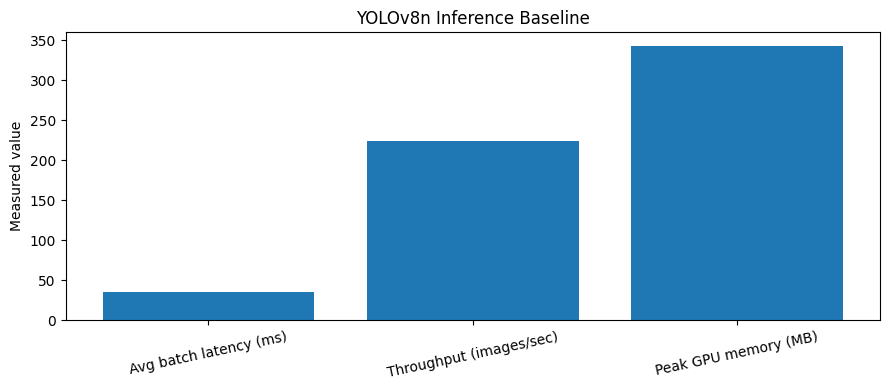

In [ ]:
# Visualize measured performance metrics
metric_names = ["Avg batch latency (ms)", "Throughput (images/sec)", "Peak GPU memory (MB)"]
metric_values = [avg_batch_latency, throughput, peak_gpu_memory_mb]

plt.figure(figsize=(9, 4))
plt.bar(metric_names, metric_values)
plt.title("YOLOv8n Inference Baseline")
plt.ylabel("Measured value")
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

In [ ]:
# Download the baseline CSV to your computer
from google.colab import files
files.download("skill9_baseline_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>